<a href="https://colab.research.google.com/github/subodhbhatta67/Supervised-Learning-Models-/blob/main/supervised_learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [335]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings('ignore')

In [336]:
from google.colab import userdata
import requests
import pandas as pd
from io import StringIO

token = userdata.get('GITHUB_TOKEN')

username = "subodhbhatta67"
repo = "Supervised-Learning-Models-"
filename = "adult_full.csv"

url = f"https://api.github.com/repos/{username}/{repo}/contents/{filename}?ref=main"

headers = {
    "Authorization": f"Bearer {token}",
    "Accept": "application/vnd.github.raw"
}

response = requests.get(url, headers=headers)

response.raise_for_status()

df = pd.read_csv(StringIO(response.text))

# EDA

In [337]:
df.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [338]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             48842 non-null  int64 
 1   workclass       48842 non-null  object
 2   fnlwgt          48842 non-null  int64 
 3   education       48842 non-null  object
 4   education-num   48842 non-null  int64 
 5   marital-status  48842 non-null  object
 6   occupation      48842 non-null  object
 7   relationship    48842 non-null  object
 8   race            48842 non-null  object
 9   sex             48842 non-null  object
 10  capital-gain    48842 non-null  int64 
 11  capital-loss    48842 non-null  int64 
 12  hours-per-week  48842 non-null  int64 
 13  native-country  48842 non-null  object
 14  income          48842 non-null  object
dtypes: int64(6), object(9)
memory usage: 5.6+ MB


In [339]:
df.describe()

,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week
count,48842.000000,4.884200e+04,48842.000000,48842.000000,48842.000000,48842.000000
mean,38.643585,1.896641e+05,10.078089,1079.067626,87.502314,40.422382
std,13.710510,1.056040e+05,2.570973,7452.019058,403.004552,12.391444
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.175505e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.781445e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.376420e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.490400e+06,16.000000,99999.000000,4356.000000,99.000000


In [340]:
df.columns

Index(['age', 'workclass', 'fnlwgt', 'education', 'education-num',
       'marital-status', 'occupation', 'relationship', 'race', 'sex',
       'capital-gain', 'capital-loss', 'hours-per-week', 'native-country',
       'income'],
      dtype='object')

In [341]:
df['workclass'].value_counts()

,count
workclass,
Private,33906
Self-emp-not-inc,3862
Local-gov,3136
?,2799
State-gov,1981
Self-emp-inc,1695
Federal-gov,1432
Without-pay,21
Never-worked,10


In [342]:
df['education'].value_counts()

,count
education,
HS-grad,15784
Some-college,10878
Bachelors,8025
Masters,2657
Assoc-voc,2061
11th,1812
Assoc-acdm,1601
10th,1389
7th-8th,955


In [343]:
df['marital-status'].value_counts()


,count
marital-status,
Married-civ-spouse,22379
Never-married,16117
Divorced,6633
Separated,1530
Widowed,1518
Married-spouse-absent,628
Married-AF-spouse,37


In [344]:
df['occupation'].value_counts()

,count
occupation,
Prof-specialty,6172
Craft-repair,6112
Exec-managerial,6086
Adm-clerical,5611
Sales,5504
Other-service,4923
Machine-op-inspct,3022
?,2809
Transport-moving,2355


In [345]:
df['relationship'].value_counts()

,count
relationship,
Husband,19716
Not-in-family,12583
Own-child,7581
Unmarried,5125
Wife,2331
Other-relative,1506


In [346]:
df['race'].value_counts()

,count
race,
White,41762
Black,4685
Asian-Pac-Islander,1519
Amer-Indian-Eskimo,470
Other,406


In [347]:
df['sex'].value_counts()

,count
sex,
Male,32650
Female,16192


In [348]:
df['native-country'].value_counts()

,count
native-country,
United-States,43832
Mexico,951
?,857
Philippines,295
Germany,206
Puerto-Rico,184
Canada,182
El-Salvador,155
India,151


In [349]:
df.replace('?', np.nan, inplace=True)

In [350]:
df.isnull().sum()

,0
age,0
workclass,2799
fnlwgt,0
education,0
education-num,0
marital-status,0
occupation,2809
relationship,0
race,0
sex,0


In [351]:
df.columns

Index(['age', 'workclass', 'fnlwgt', 'education', 'education-num',
       'marital-status', 'occupation', 'relationship', 'race', 'sex',
       'capital-gain', 'capital-loss', 'hours-per-week', 'native-country',
       'income'],
      dtype='object')

# VISUALIZATIONS

<Axes: xlabel='age', ylabel='Count'>

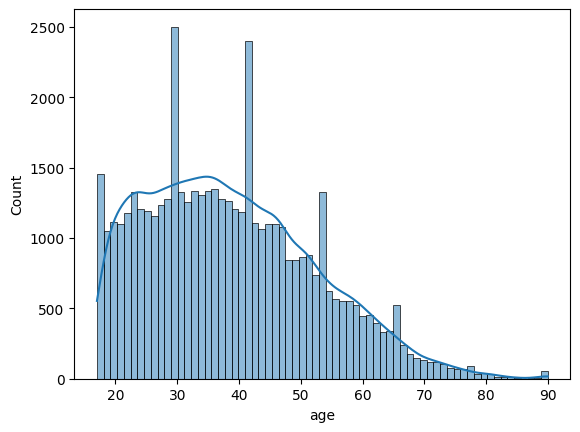

In [352]:
sns.histplot(df, x ='age', kde= True)

<Axes: xlabel='fnlwgt', ylabel='Count'>

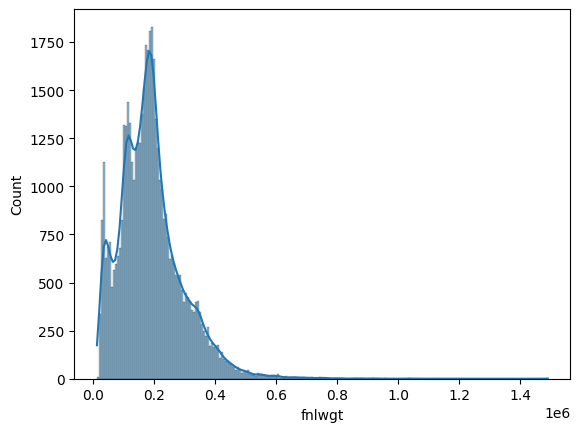

In [353]:
sns.histplot(df, x='fnlwgt', kde = True)

<Axes: xlabel='capital-gain', ylabel='Count'>

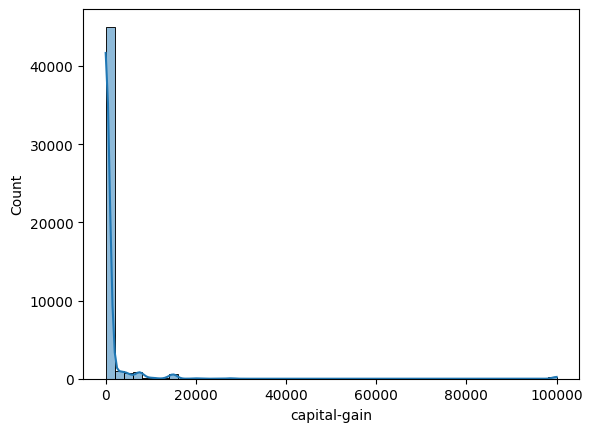

In [354]:
sns.histplot(df, x='capital-gain', kde = True, bins = 50)


<Axes: xlabel='capital-loss', ylabel='Count'>

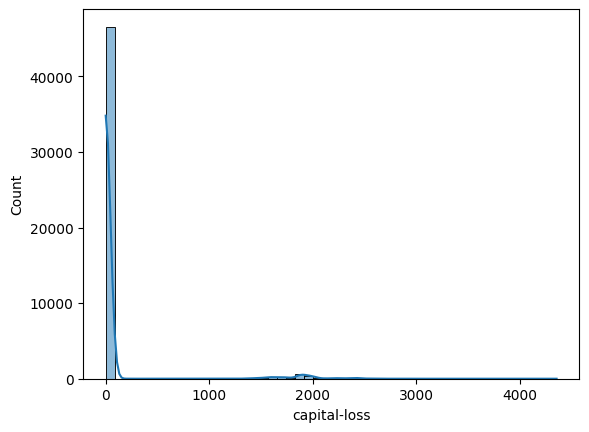

In [355]:
sns.histplot(df, x='capital-loss', kde = True, bins = 50)


<Axes: xlabel='hours-per-week', ylabel='Count'>

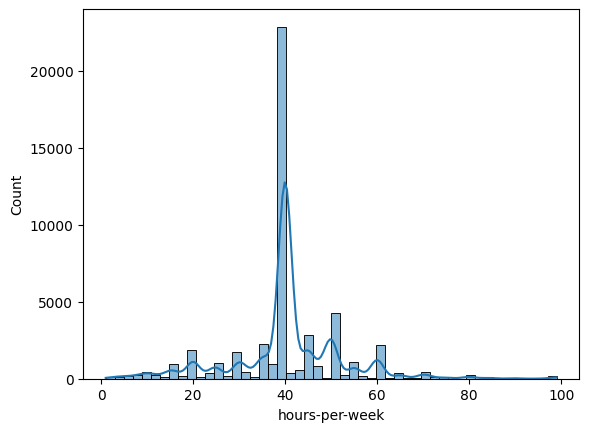

In [356]:
sns.histplot(df, x='hours-per-week', kde = True, bins = 50)


In [357]:
df


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48837,39,Private,215419,Bachelors,13,Divorced,Prof-specialty,Not-in-family,White,Female,0,0,36,United-States,<=50K
48838,64,NaN,321403,HS-grad,9,Widowed,NaN,Other-relative,Black,Male,0,0,40,United-States,<=50K
48839,38,Private,374983,Bachelors,13,Married-civ-spouse,Prof-specialty,Husband,White,Male,0,0,50,United-States,<=50K
48840,44,Private,83891,Bachelors,13,Divorced,Adm-clerical,Own-child,Asian-Pac-Islander,Male,5455,0,40,United-States,<=50K


<Axes: xlabel='income', ylabel='hours-per-week'>

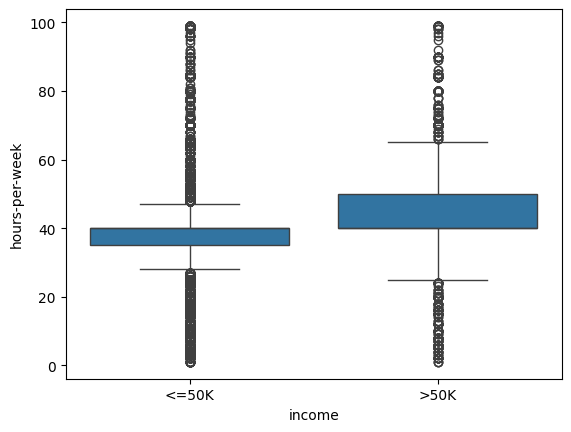

In [358]:
sns.boxplot(df, x = 'income', y = 'hours-per-week')
# so this is simply the graph that is used numerical data vs categorical target data

<Axes: xlabel='income', ylabel='capital-loss'>

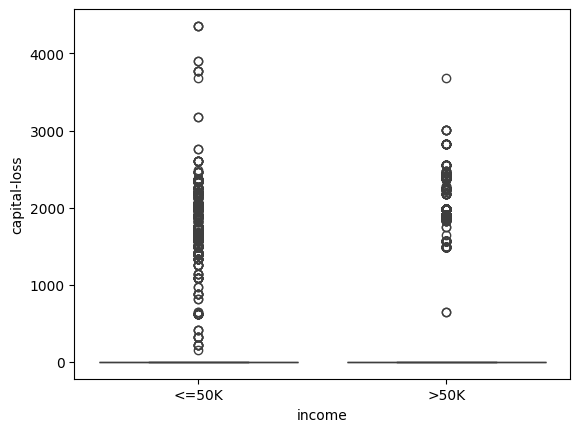

In [359]:
sns.boxplot(df, x = 'income', y = 'capital-loss')

<Axes: xlabel='income', ylabel='capital-gain'>

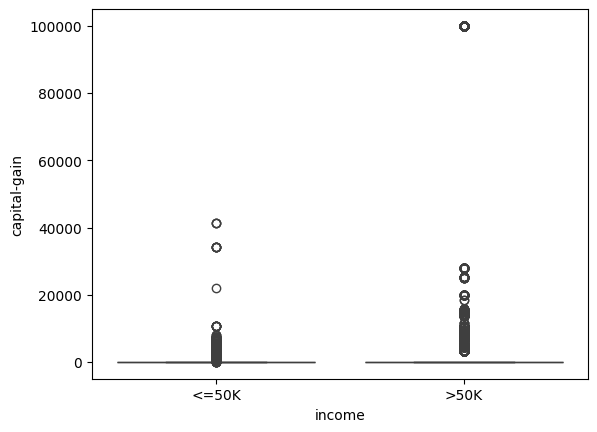

In [360]:
sns.boxplot(df, x = 'income', y = 'capital-gain')

<Axes: xlabel='income', ylabel='fnlwgt'>

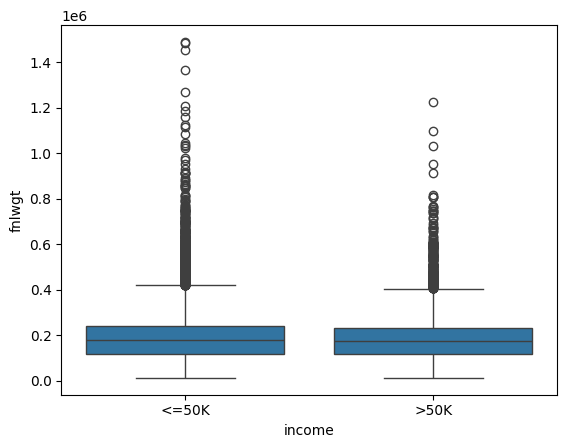

In [361]:
sns.boxplot(df, x = 'income', y = 'fnlwgt')
# not usefull data as it is same for both the category and it is hard to identify

<Axes: xlabel='income', ylabel='age'>

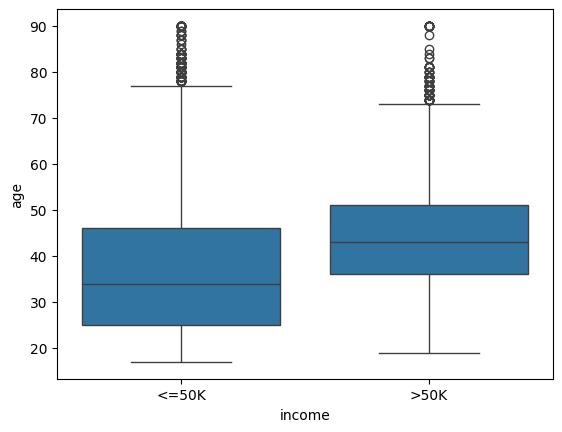

In [362]:
sns.boxplot(df, x = 'income', y = 'age')

In [363]:
from scipy.stats import chi2_contingency

table = pd.crosstab(df['workclass'], df['income'])

chi2, p, dof, expected = chi2_contingency(table)

print("Chi-square:", chi2)
print("P-value:", p)

#p < 0.05: Evidence of an association between the two variables
# p >= 0.05: Insufficient evidence of an association.

Chi-square: 1238.990039222109
P-value: 2.6121798441462815e-263


In [364]:

table = pd.crosstab(df['education'], df['income'])

chi2, p, dof, expected = chi2_contingency(table)

print("Chi-square:", chi2)
print("P-value:", p)

Chi-square: 6537.972961360963
P-value: 0.0


In [365]:

table = pd.crosstab(df['marital-status'],df['income'] )

chi2, p, dof, expected = chi2_contingency(table)

print("Chi-square:", chi2)
print("P-value:", p)

Chi-square: 9816.015037266438
P-value: 0.0


In [366]:

table = pd.crosstab(df['occupation'],df['income'] )

chi2, p, dof, expected = chi2_contingency(table)

print("Chi-square:", chi2)
print("P-value:", p)

Chi-square: 5502.144900139091
P-value: 0.0


In [367]:

table = pd.crosstab(df['relationship'], df['income'])

chi2, p, dof, expected = chi2_contingency(table)

print("Chi-square:", chi2)
print("P-value:", p)

Chi-square: 10088.722490152224
P-value: 0.0


In [368]:


table = pd.crosstab(df['race'], df['income'] )

chi2, p, dof, expected = chi2_contingency(table)

print("Chi-square:", chi2)
print("P-value:", p)

Chi-square: 487.026286837627
P-value: 4.284377710223499e-104


In [369]:

table = pd.crosstab(df['sex'], df['income'])

chi2, p, dof, expected = chi2_contingency(table)

print("Chi-square:", chi2)
print("P-value:", p)

Chi-square: 2248.847679013691
P-value: 0.0


In [370]:

table = pd.crosstab(df['native-country'], df['income'])

chi2, p, dof, expected = chi2_contingency(table)

print("Chi-square:", chi2)
print("P-value:", p)

Chi-square: 451.17601430219054
P-value: 4.9465504983432925e-71


In [371]:
table = pd.crosstab(df['education-num'], df['income'])

chi2, p, dof, expected = chi2_contingency(table)

print("Chi-square:", chi2)
print("P-value:", p)

Chi-square: 6537.972961360963
P-value: 0.0


In [372]:
features = df.drop(columns=['income'])
target = df['income']

In [373]:
def cramers_v(feature, target):
    table = pd.crosstab(feature, target)

    chi2 = chi2_contingency(table)[0]
    n = table.to_numpy().sum()

    rows, cols = table.shape

    return np.sqrt(
        chi2 / (n * min(rows - 1, cols - 1))
    )

In [374]:
print(cramers_v(df['education'], df['income']))
print(cramers_v(df['workclass'], df['income']))
print(cramers_v(df['occupation'], df['income']))


print(cramers_v(df['marital-status'], df['income']))
print(cramers_v(df['relationship'], df['income']))
print(cramers_v(df['race'], df['income']))

print(cramers_v(df['sex'], df['income']))
print(cramers_v(df['native-country'], df['income']))
print(cramers_v(df['education-num'], df['income']))


0.3658683488509228
0.16404088398948963
0.34572546720102665
0.4483022183099439
0.4544868985792051
0.09985722238766276
0.21457706493774975
0.09696617224585236
0.3658683488509228


# Data cleaning


In [375]:
df.isnull().sum()

,0
age,0
workclass,2799
fnlwgt,0
education,0
education-num,0
marital-status,0
occupation,2809
relationship,0
race,0
sex,0


In [376]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             48842 non-null  int64 
 1   workclass       46043 non-null  object
 2   fnlwgt          48842 non-null  int64 
 3   education       48842 non-null  object
 4   education-num   48842 non-null  int64 
 5   marital-status  48842 non-null  object
 6   occupation      46033 non-null  object
 7   relationship    48842 non-null  object
 8   race            48842 non-null  object
 9   sex             48842 non-null  object
 10  capital-gain    48842 non-null  int64 
 11  capital-loss    48842 non-null  int64 
 12  hours-per-week  48842 non-null  int64 
 13  native-country  47985 non-null  object
 14  income          48842 non-null  object
dtypes: int64(6), object(9)
memory usage: 5.6+ MB


In [377]:
cat_cols = df.select_dtypes(include=['object']).columns

for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

In [378]:
df.isnull().sum()


,0
age,0
workclass,0
fnlwgt,0
education,0
education-num,0
marital-status,0
occupation,0
relationship,0
race,0
sex,0


In [379]:
df.duplicated().sum()

np.int64(53)

In [380]:
df.drop_duplicates(inplace=True)

In [381]:
df.duplicated().sum()

np.int64(0)

In [382]:
df['workclass'].value_counts()

,count
workclass,
Private,36654
Self-emp-not-inc,3861
Local-gov,3136
State-gov,1981
Self-emp-inc,1694
Federal-gov,1432
Without-pay,21
Never-worked,10


In [383]:
df['education'].value_counts()


,count
education,
HS-grad,15770
Some-college,10862
Bachelors,8013
Masters,2656
Assoc-voc,2060
11th,1812
Assoc-acdm,1601
10th,1389
7th-8th,954


In [384]:
df['education-num'].value_counts()

,count
education-num,
9,15770
10,10862
13,8013
14,2656
11,2060
7,1812
12,1601
6,1389
4,954


In [385]:
df.groupby('education')['education-num'].unique()

,education-num
education,
10th,[6]
11th,[7]
12th,[8]
1st-4th,[2]
5th-6th,[3]
7th-8th,[4]
9th,[5]
Assoc-acdm,[12]
Assoc-voc,[11]


In [386]:
df['marital-status'].value_counts()

,count
marital-status,
Married-civ-spouse,22366
Never-married,16081
Divorced,6630
Separated,1530
Widowed,1518
Married-spouse-absent,627
Married-AF-spouse,37


In [387]:
df['occupation'].value_counts()

,count
occupation,
Prof-specialty,8969
Craft-repair,6102
Exec-managerial,6082
Adm-clerical,5606
Sales,5501
Other-service,4919
Machine-op-inspct,3017
Transport-moving,2355
Handlers-cleaners,2071


In [388]:
df = df.drop(columns=['education-num'])

df = pd.get_dummies(df, columns=['education'], dtype=int)

In [389]:
df.columns

Index(['age', 'workclass', 'fnlwgt', 'marital-status', 'occupation',
       'relationship', 'race', 'sex', 'capital-gain', 'capital-loss',
       'hours-per-week', 'native-country', 'income', 'education_10th',
       'education_11th', 'education_12th', 'education_1st-4th',
       'education_5th-6th', 'education_7th-8th', 'education_9th',
       'education_Assoc-acdm', 'education_Assoc-voc', 'education_Bachelors',
       'education_Doctorate', 'education_HS-grad', 'education_Masters',
       'education_Preschool', 'education_Prof-school',
       'education_Some-college'],
      dtype='object')

In [390]:
df['relationship'].value_counts()

,count
relationship,
Husband,19703
Not-in-family,12557
Own-child,7568
Unmarried,5124
Wife,2331
Other-relative,1506


In [391]:
df['race'].value_counts()

,count
race,
White,41713
Black,4683
Asian-Pac-Islander,1517
Amer-Indian-Eskimo,470
Other,406


In [392]:
df['sex'].value_counts()

,count
sex,
Male,32614
Female,16175


In [393]:
df['is_female'] = df['sex'].map({
    'Female': 1,
    'Male': 0
})

df = df.drop(columns=['sex'])

In [394]:
df

,age,workclass,fnlwgt,marital-status,occupation,relationship,race,capital-gain,capital-loss,hours-per-week,...,education_Assoc-acdm,education_Assoc-voc,education_Bachelors,education_Doctorate,education_HS-grad,education_Masters,education_Preschool,education_Prof-school,education_Some-college,is_female
0,39,State-gov,77516,Never-married,Adm-clerical,Not-in-family,White,2174,0,40,...,0,0,1,0,0,0,0,0,0,0
1,50,Self-emp-not-inc,83311,Married-civ-spouse,Exec-managerial,Husband,White,0,0,13,...,0,0,1,0,0,0,0,0,0,0
2,38,Private,215646,Divorced,Handlers-cleaners,Not-in-family,White,0,0,40,...,0,0,0,0,1,0,0,0,0,0
3,53,Private,234721,Married-civ-spouse,Handlers-cleaners,Husband,Black,0,0,40,...,0,0,0,0,0,0,0,0,0,0
4,28,Private,338409,Married-civ-spouse,Prof-specialty,Wife,Black,0,0,40,...,0,0,1,0,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48837,39,Private,215419,Divorced,Prof-specialty,Not-in-family,White,0,0,36,...,0,0,1,0,0,0,0,0,0,1
48838,64,Private,321403,Widowed,Prof-specialty,Other-relative,Black,0,0,40,...,0,0,0,0,1,0,0,0,0,0
48839,38,Private,374983,Married-civ-spouse,Prof-specialty,Husband,White,0,0,50,...,0,0,1,0,0,0,0,0,0,0
48840,44,Private,83891,Divorced,Adm-clerical,Own-child,Asian-Pac-Islander,5455,0,40,...,0,0,1,0,0,0,0,0,0,0


In [395]:
df = pd.get_dummies(df, columns=['race'], dtype=int)

In [396]:
df.columns

Index(['age', 'workclass', 'fnlwgt', 'marital-status', 'occupation',
       'relationship', 'capital-gain', 'capital-loss', 'hours-per-week',
       'native-country', 'income', 'education_10th', 'education_11th',
       'education_12th', 'education_1st-4th', 'education_5th-6th',
       'education_7th-8th', 'education_9th', 'education_Assoc-acdm',
       'education_Assoc-voc', 'education_Bachelors', 'education_Doctorate',
       'education_HS-grad', 'education_Masters', 'education_Preschool',
       'education_Prof-school', 'education_Some-college', 'is_female',
       'race_Amer-Indian-Eskimo', 'race_Asian-Pac-Islander', 'race_Black',
       'race_Other', 'race_White'],
      dtype='object')

In [397]:
df['native-country'].value_counts()

,count
native-country,
United-States,44647
Mexico,943
Philippines,294
Germany,206
Puerto-Rico,184
Canada,182
El-Salvador,155
India,151
Cuba,138


In [398]:
df = pd.get_dummies(df, columns=['native-country'], dtype=int)

In [399]:
df.columns

Index(['age', 'workclass', 'fnlwgt', 'marital-status', 'occupation',
       'relationship', 'capital-gain', 'capital-loss', 'hours-per-week',
       'income', 'education_10th', 'education_11th', 'education_12th',
       'education_1st-4th', 'education_5th-6th', 'education_7th-8th',
       'education_9th', 'education_Assoc-acdm', 'education_Assoc-voc',
       'education_Bachelors', 'education_Doctorate', 'education_HS-grad',
       'education_Masters', 'education_Preschool', 'education_Prof-school',
       'education_Some-college', 'is_female', 'race_Amer-Indian-Eskimo',
       'race_Asian-Pac-Islander', 'race_Black', 'race_Other', 'race_White',
       'native-country_Cambodia', 'native-country_Canada',
       'native-country_China', 'native-country_Columbia',
       'native-country_Cuba', 'native-country_Dominican-Republic',
       'native-country_Ecuador', 'native-country_El-Salvador',
       'native-country_England', 'native-country_France',
       'native-country_Germany', 'native-c

In [400]:
df

,age,workclass,fnlwgt,marital-status,occupation,relationship,capital-gain,capital-loss,hours-per-week,income,...,native-country_Portugal,native-country_Puerto-Rico,native-country_Scotland,native-country_South,native-country_Taiwan,native-country_Thailand,native-country_Trinadad&Tobago,native-country_United-States,native-country_Vietnam,native-country_Yugoslavia
0,39,State-gov,77516,Never-married,Adm-clerical,Not-in-family,2174,0,40,<=50K,...,0,0,0,0,0,0,0,1,0,0
1,50,Self-emp-not-inc,83311,Married-civ-spouse,Exec-managerial,Husband,0,0,13,<=50K,...,0,0,0,0,0,0,0,1,0,0
2,38,Private,215646,Divorced,Handlers-cleaners,Not-in-family,0,0,40,<=50K,...,0,0,0,0,0,0,0,1,0,0
3,53,Private,234721,Married-civ-spouse,Handlers-cleaners,Husband,0,0,40,<=50K,...,0,0,0,0,0,0,0,1,0,0
4,28,Private,338409,Married-civ-spouse,Prof-specialty,Wife,0,0,40,<=50K,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48837,39,Private,215419,Divorced,Prof-specialty,Not-in-family,0,0,36,<=50K,...,0,0,0,0,0,0,0,1,0,0
48838,64,Private,321403,Widowed,Prof-specialty,Other-relative,0,0,40,<=50K,...,0,0,0,0,0,0,0,1,0,0
48839,38,Private,374983,Married-civ-spouse,Prof-specialty,Husband,0,0,50,<=50K,...,0,0,0,0,0,0,0,1,0,0
48840,44,Private,83891,Divorced,Adm-clerical,Own-child,5455,0,40,<=50K,...,0,0,0,0,0,0,0,1,0,0


In [401]:
df = pd.get_dummies(df, columns=['marital-status'], dtype=int)

In [402]:
df = pd.get_dummies(df, columns=['workclass'], dtype=int)

In [403]:
df = pd.get_dummies(df, columns=['occupation'], dtype=int)

In [404]:
df = pd.get_dummies(df, columns=['relationship'], dtype=int)

In [405]:
df.shape

(48789, 104)

# Feature Transformation

age                0.556564
capital-gain      11.888142
capital-loss       4.566984
hours-per-week     0.239647
fnlwgt             1.439669
dtype: float64


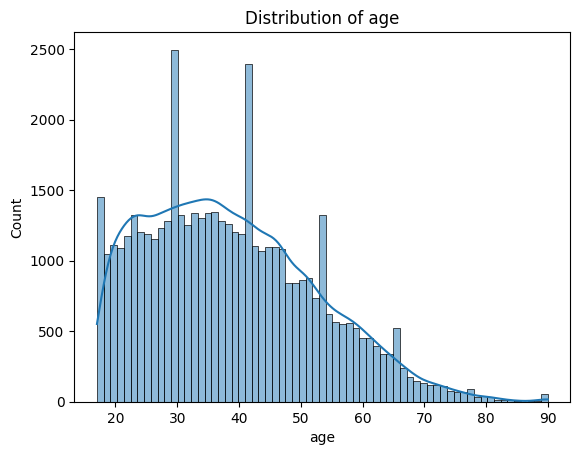

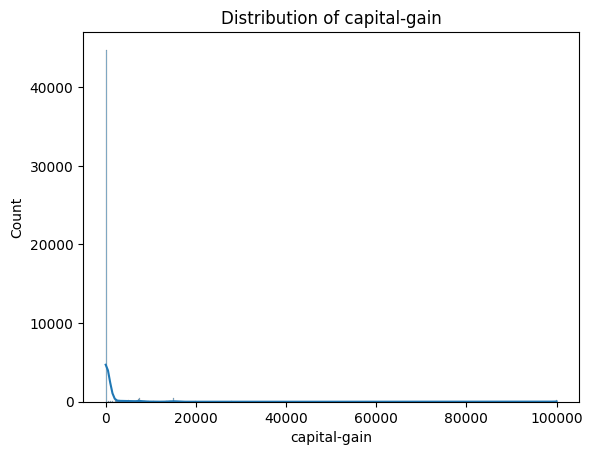

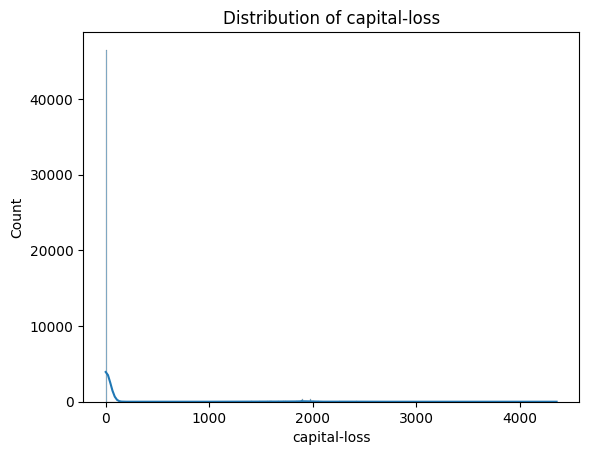

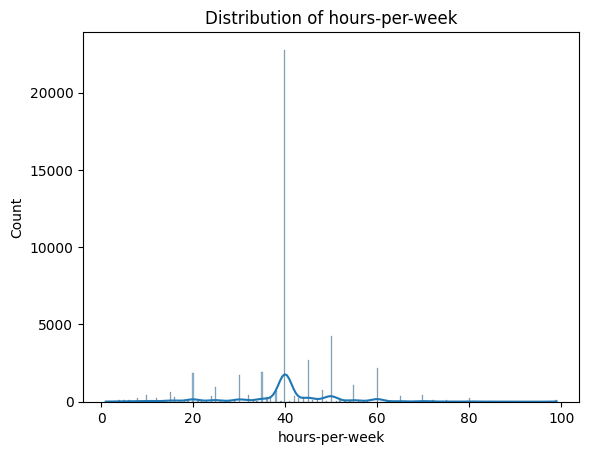

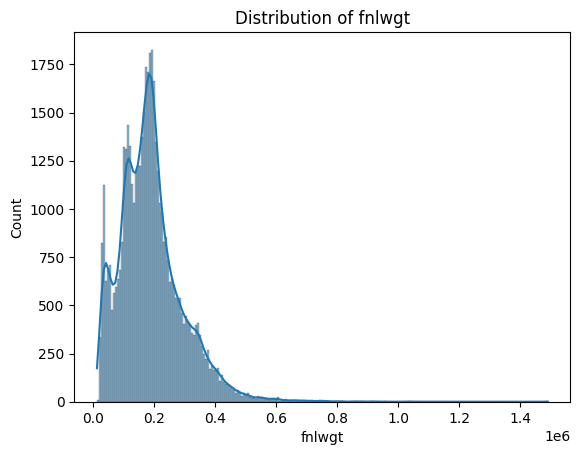

In [406]:
num_cols = ['age', 'capital-gain', 'capital-loss', 'hours-per-week', 'fnlwgt']

print(df[num_cols].skew())

for col in num_cols:
    sns.histplot(df[col], kde=True)
    plt.title(f'Distribution of {col}')
    plt.show()

In [407]:
df['capital-gain_log'] = np.log1p(df['capital-gain'])

In [408]:
df

,age,fnlwgt,capital-gain,capital-loss,hours-per-week,income,education_10th,education_11th,education_12th,education_1st-4th,...,occupation_Sales,occupation_Tech-support,occupation_Transport-moving,relationship_Husband,relationship_Not-in-family,relationship_Other-relative,relationship_Own-child,relationship_Unmarried,relationship_Wife,capital-gain_log
0,39,77516,2174,0,40,<=50K,0,0,0,0,...,0,0,0,0,1,0,0,0,0,7.684784
1,50,83311,0,0,13,<=50K,0,0,0,0,...,0,0,0,1,0,0,0,0,0,0.000000
2,38,215646,0,0,40,<=50K,0,0,0,0,...,0,0,0,0,1,0,0,0,0,0.000000
3,53,234721,0,0,40,<=50K,0,1,0,0,...,0,0,0,1,0,0,0,0,0,0.000000
4,28,338409,0,0,40,<=50K,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48837,39,215419,0,0,36,<=50K,0,0,0,0,...,0,0,0,0,1,0,0,0,0,0.000000
48838,64,321403,0,0,40,<=50K,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0.000000
48839,38,374983,0,0,50,<=50K,0,0,0,0,...,0,0,0,1,0,0,0,0,0,0.000000
48840,44,83891,5455,0,40,<=50K,0,0,0,0,...,0,0,0,0,0,0,1,0,0,8.604471


In [409]:
df['capital-gain_log'].skew()

np.float64(3.1114490317406385)

In [410]:
df = df.drop(columns=['capital-gain'])
df = df.rename(columns={'capital-gain_log': 'capital-gain'})

In [411]:
df

,age,fnlwgt,capital-loss,hours-per-week,income,education_10th,education_11th,education_12th,education_1st-4th,education_5th-6th,...,occupation_Sales,occupation_Tech-support,occupation_Transport-moving,relationship_Husband,relationship_Not-in-family,relationship_Other-relative,relationship_Own-child,relationship_Unmarried,relationship_Wife,capital-gain
0,39,77516,0,40,<=50K,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,7.684784
1,50,83311,0,13,<=50K,0,0,0,0,0,...,0,0,0,1,0,0,0,0,0,0.000000
2,38,215646,0,40,<=50K,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,0.000000
3,53,234721,0,40,<=50K,0,1,0,0,0,...,0,0,0,1,0,0,0,0,0,0.000000
4,28,338409,0,40,<=50K,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48837,39,215419,0,36,<=50K,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,0.000000
48838,64,321403,0,40,<=50K,0,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0.000000
48839,38,374983,0,50,<=50K,0,0,0,0,0,...,0,0,0,1,0,0,0,0,0,0.000000
48840,44,83891,0,40,<=50K,0,0,0,0,0,...,0,0,0,0,0,0,1,0,0,8.604471


In [412]:
(df['capital-loss'].eq(0).mean() * 100)

np.float64(95.32271618602553)

In [413]:
df['has_capital_loss'] = (df['capital-loss'] > 0).astype(int)

In [414]:
df

,age,fnlwgt,capital-loss,hours-per-week,income,education_10th,education_11th,education_12th,education_1st-4th,education_5th-6th,...,occupation_Tech-support,occupation_Transport-moving,relationship_Husband,relationship_Not-in-family,relationship_Other-relative,relationship_Own-child,relationship_Unmarried,relationship_Wife,capital-gain,has_capital_loss
0,39,77516,0,40,<=50K,0,0,0,0,0,...,0,0,0,1,0,0,0,0,7.684784,0
1,50,83311,0,13,<=50K,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0.000000,0
2,38,215646,0,40,<=50K,0,0,0,0,0,...,0,0,0,1,0,0,0,0,0.000000,0
3,53,234721,0,40,<=50K,0,1,0,0,0,...,0,0,1,0,0,0,0,0,0.000000,0
4,28,338409,0,40,<=50K,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0.000000,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48837,39,215419,0,36,<=50K,0,0,0,0,0,...,0,0,0,1,0,0,0,0,0.000000,0
48838,64,321403,0,40,<=50K,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0.000000,0
48839,38,374983,0,50,<=50K,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0.000000,0
48840,44,83891,0,40,<=50K,0,0,0,0,0,...,0,0,0,0,0,1,0,0,8.604471,0


In [415]:
pd.crosstab(
    df['has_capital_loss'],
    df['income'],
    normalize='index'
) * 100

income,<=50K,>50K
has_capital_loss,,
0,77.343196,22.656804
1,49.868536,50.131464


In [416]:
df['fnlwgt_log'] = np.log1p(df['fnlwgt'])

In [417]:
df['fnlwgt_log'].skew()

np.float64(-0.8360936463972457)

In [418]:
df

,age,fnlwgt,capital-loss,hours-per-week,income,education_10th,education_11th,education_12th,education_1st-4th,education_5th-6th,...,occupation_Transport-moving,relationship_Husband,relationship_Not-in-family,relationship_Other-relative,relationship_Own-child,relationship_Unmarried,relationship_Wife,capital-gain,has_capital_loss,fnlwgt_log
0,39,77516,0,40,<=50K,0,0,0,0,0,...,0,0,1,0,0,0,0,7.684784,0,11.258253
1,50,83311,0,13,<=50K,0,0,0,0,0,...,0,1,0,0,0,0,0,0.000000,0,11.330348
2,38,215646,0,40,<=50K,0,0,0,0,0,...,0,0,1,0,0,0,0,0.000000,0,12.281398
3,53,234721,0,40,<=50K,0,1,0,0,0,...,0,1,0,0,0,0,0,0.000000,0,12.366157
4,28,338409,0,40,<=50K,0,0,0,0,0,...,0,0,0,0,0,0,1,0.000000,0,12.732013
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48837,39,215419,0,36,<=50K,0,0,0,0,0,...,0,0,1,0,0,0,0,0.000000,0,12.280345
48838,64,321403,0,40,<=50K,0,0,0,0,0,...,0,0,0,1,0,0,0,0.000000,0,12.680454
48839,38,374983,0,50,<=50K,0,0,0,0,0,...,0,1,0,0,0,0,0,0.000000,0,12.834639
48840,44,83891,0,40,<=50K,0,0,0,0,0,...,0,0,0,0,1,0,0,8.604471,0,11.337286


# FEATURE ENGINEERING AND FEATURE SELECTION

In [419]:
df['income'] = df['income'].map({
    '>50K': 1,
    '<=50K': 0
})

In [420]:
df

,age,fnlwgt,capital-loss,hours-per-week,income,education_10th,education_11th,education_12th,education_1st-4th,education_5th-6th,...,occupation_Transport-moving,relationship_Husband,relationship_Not-in-family,relationship_Other-relative,relationship_Own-child,relationship_Unmarried,relationship_Wife,capital-gain,has_capital_loss,fnlwgt_log
0,39,77516,0,40,0,0,0,0,0,0,...,0,0,1,0,0,0,0,7.684784,0,11.258253
1,50,83311,0,13,0,0,0,0,0,0,...,0,1,0,0,0,0,0,0.000000,0,11.330348
2,38,215646,0,40,0,0,0,0,0,0,...,0,0,1,0,0,0,0,0.000000,0,12.281398
3,53,234721,0,40,0,0,1,0,0,0,...,0,1,0,0,0,0,0,0.000000,0,12.366157
4,28,338409,0,40,0,0,0,0,0,0,...,0,0,0,0,0,0,1,0.000000,0,12.732013
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48837,39,215419,0,36,0,0,0,0,0,0,...,0,0,1,0,0,0,0,0.000000,0,12.280345
48838,64,321403,0,40,0,0,0,0,0,0,...,0,0,0,1,0,0,0,0.000000,0,12.680454
48839,38,374983,0,50,0,0,0,0,0,0,...,0,1,0,0,0,0,0,0.000000,0,12.834639
48840,44,83891,0,40,0,0,0,0,0,0,...,0,0,0,0,1,0,0,8.604471,0,11.337286


In [421]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

In [422]:
X = df.drop('income', axis=1)
y = df['income']

In [423]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, stratify=y, test_size=0.2, random_state=42)

In [424]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [425]:
models = LogisticRegression()

In [426]:
models.fit(X_train_scaled, y_train)

LogisticRegression()

In [427]:
y_pred = models.predict(X_test_scaled)

In [428]:
print(type(y_pred))
print(y_pred)

<class 'numpy.ndarray'>
[0 0 0 ... 0 0 0]


In [429]:
accuracy_score(y_test, y_pred)

0.8469973355195737

In [430]:
confusion_matrix(y_test, y_pred)

array([[6870,  552],
       [ 941, 1395]])

In [431]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.88      0.93      0.90      7422
           1       0.72      0.60      0.65      2336

    accuracy                           0.85      9758
   macro avg       0.80      0.76      0.78      9758
weighted avg       0.84      0.85      0.84      9758



# USE OF CROSS VALIDATION

In [432]:
from sklearn.model_selection import cross_val_score

In [433]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [434]:
scores = cross_val_score(models,X_scaled,y,cv=5,scoring = 'accuracy')

In [435]:
print(scores)

[0.84494774 0.84341053 0.84853454 0.84627998 0.84462437]


In [436]:
print(scores.mean())

0.8455594307106423


# SVM

In [437]:
from sklearn.svm import SVC

In [438]:
model_svm = SVC(C = 2, kernel = 'rbf')

In [439]:
model_svm.fit(X_train_scaled,y_train)

SVC(C=2)

In [440]:
y_pred = model_svm.predict(X_test_scaled)

In [441]:
accuracy_score(y_test, y_pred)

0.8479196556671449

In [442]:
confusion_matrix(y_test, y_pred)

array([[6884,  538],
       [ 946, 1390]])

In [443]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.88      0.93      0.90      7422
           1       0.72      0.60      0.65      2336

    accuracy                           0.85      9758
   macro avg       0.80      0.76      0.78      9758
weighted avg       0.84      0.85      0.84      9758



In [334]:
# cross validation

scores1 = cross_val_score(model_svm,X_scaled,y,cv=5,scoring = 'accuracy')

In [445]:
print(scores1)

[0.8451527  0.83992621 0.84197581 0.84453782 0.8486215 ]


In [446]:
print(scores1.mean())

0.8440428083931648


# KNN

In [449]:
from sklearn.neighbors import KNeighborsClassifier

In [450]:
model_knn = KNeighborsClassifier(n_neighbors= 5)

In [451]:
model_knn.fit(X_train_scaled, y_train)

KNeighborsClassifier()

In [452]:
model_knn.score(X_test_scaled, y_test )

0.827116212338594

In [453]:
scores2 = cross_val_score(model_knn,X_scaled,y,cv=5,scoring = 'accuracy')

In [454]:
print(scores2)

[0.82609141 0.82506661 0.82598893 0.82209469 0.82084657]


In [456]:
print(scores2.mean())

0.8240176439141564
